# Select Region of Decay Curve Fitting Example (NLSF & MLE)

This example fits a selected region of the tge simulated, mono-exponential fluorescence lifetime image (FLI) pixel by pixel -- **not over the entire decay, but only over the part of its tail between 10% and 80% of the way from the peak to the end of the window** -- with two estimators, and compares them against the known ground truth:

- **Non-linear least squares (NLSF)**: minimizes the weighted sum of squared residuals between the IRF-convolved model and the decay. 
- **Maximum likelihood estimation (MLE)**: maximizes the Poisson log-likelihood of the photon counts directly.

**Tail fitting.** The *tail* is the part of the decay after its peak. Here the first 10% of the tail -- the peak and the early decay, where the IRF shape matters most -- and the last 20% -- the late gates, where dark counts dominate -- are excluded, and only the gates in between are fitted. The forward model is still evaluated (and convolved with the IRF) over the whole trace; only the residuals, the likelihood and the fit statistics are restricted to the fit window, via the fitters' `fit_indices=(start_gate, end_gate)` option.

This example walks through:
- Simulating a whole FLI image with known lifetimes (as in the "Whole Image Simulation" example)
- Choosing the tail window from the decay peak
- Comparing NLSF and MLE on a single pixel, fitted over the tail window
- Fitting the whole image with NLSF and with MLE over the tail window
- Comparing the fitted lifetime maps and their distributions with the ground truth
- Inspecting the fit and residuals at individual pixels

<small>Author - Vikas</small>

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "ex_helper")  # local helper for synthetic image generation

from sim_general_image import LettersShape, ROIMaskGenerator

from pyfli.analysis.utils import plot_pixel_diagnostic, random_true_pixel
from pyfli.analyticalWorkflow import AnalyticalHelpers
from pyfli.data_cc import Normalization
from pyfli.data_text import MessageDisplay
from pyfli.data_vnp import ColorProcessor, DataViewer, Plotter
from pyfli.io import DataOperations
from pyfli.simulator import FLIModelImageGenerator
from pyfli.solver import (
    BaseFLIFitter,
    BinnedFLIFitter,
    FittingComparator,
    FLICPUProcessor,
    MLEFLIFitter,
)

## Generating a test image

A test image is simulated to compare the ground truth against the estimated values. In this example, a 128 x 512 image is generated with the letters "F", "L", "I", "M". Each letter is assigned a different intensity value (grayscale bit size) and a different lifetime: 0.7 ± 0.05 ns, 0.8 ± 0.05 ns, 0.9 ± 0.05 ns, and 1.0 ± 0.05 ns, respectively.

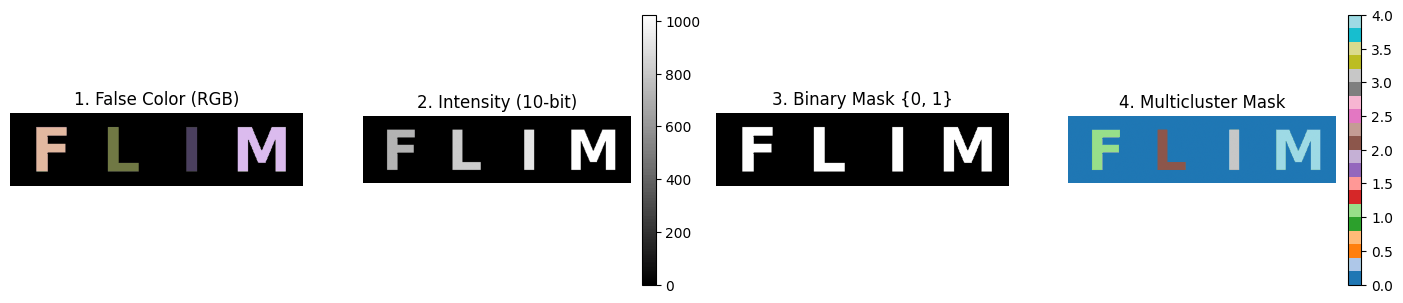

In [2]:
h, w = 128, 512
generator = ROIMaskGenerator((h, w), top=10, bottom=10, left=10, right=10)
FLIM_letters = LettersShape(letters=("F", "L", "I", "M"), gap=0.15)

custom_intensities = [0.7, 0.8, 0.9, 1.0]
# Preview the generated image
_ = generator.plot_preview(
    FLIM_letters,
    bit_depth=10,
    intensities=custom_intensities,
    show=True,
)

## Loading the IRF

In [3]:
# Path to the local IRF file
IRF_PATH = "<select file/folder path>"

In [4]:
loader = DataOperations(irf_path=IRF_PATH)
irf_data = loader.load_irf()

gate_delay = 12.5 / irf_data.shape[2]
num_gates = irf_data.shape[2]
freq = AnalyticalHelpers(
    laser_period=12.5, gate_delay=gate_delay, num_gate=num_gates
).freq_computation()

INFO:pyfli:Initiating IRF load from: <select file/folder path>


## Simulation configuration

`MODEL_TYPE` selects the decay model for both the simulation and the fits. Setting `mono_fraction` to 1.0 forces every simulated pixel to be mono-exponential.

In [5]:
SEED = 0
MODEL_TYPE = "mono-exponential"

# Your constant, default configuration
BASE_CONFIG = {
    # Modular Noise
    "jitter": False,  # offset artifact (due to jitter)
    "dcr_on": True,  # Dark Count Rate (thermal background)
    "poisson": False,  # Shot noise — Large detector only
    "qe_on": True,  # Quantum efficiency scaling
    "read_noise_on": False,  # Gaussian read noise — Large detector only
    # Sensor
    "sensor_type": "discrete",  # "continuous" | "discrete"
    "bit": 12,
    "dcr": 0.08,  # Mean dark counts per bin
    "laser_feq": freq[1],  # Laser repetition rate (MHz) → period = 12.5 ns
    "round_on": True,  # Round photon counts to integers — Macro_sim only
    "clip_on": True,  # Clip at bit-depth ceiling — Macro_sim: max_adc_val; TCSPC: max_bin_count
    # Fluorescence Physics (FLI / FRET)
    "tau2": (1, 1),  # τ₂ ~ TruncNormal(mu=1 ns, sigma=0.5 ns)
    "tau2_dist": "beta",  # if dist "beta" or "normal" (default)
    "efficiency": (1, 1),  # FRET efficiency E ~ Beta(2, 5)  → [0.1, 1.0]
    "A1_fraction": (1, 1),  # Amplitude fraction A₁ ~ Beta(2, 5) → [0.05, 0.95]
    "photo_count": (2, 5),  # Peak intensity ~ Beta(2, 5) × max_adc - large detectors
    "mono_fraction": 1.0,  # Fraction of pixels forced mono-exponential (0.0 = all bi-exp)
    "n_cycles": (1_500_000, 2_000_000),  # Accumulation cycles — for photon counter
}

Different ROIs (letter areas, in this case) are assigned different lifetimes.

In [6]:
def get_config(**kwargs):
    """Create a config by overriding defaults with specific test parameters."""
    config = BASE_CONFIG.copy()
    config.update(kwargs)
    return config


ROI0 = {}
ROI1 = get_config(
    tau2_beta_range=(0.05, 0.5),
)
ROI2 = get_config(
    tau2_beta_range=(0.05, 0.7),
)
ROI3 = get_config(
    tau2_beta_range=(0.05, 0.9),
)
ROI4 = get_config(
    tau2_beta_range=(0.05, 1.1),
)

In [7]:
img_intensity = generator.generate_intensity_image(
    FLIM_letters, intensities=custom_intensities
)
img_cluster = generator.generate_cluster_mask(FLIM_letters)
b_bool_mask = generator.generate_binary_mask(FLIM_letters)

np.random.seed(SEED)
simulated_img = FLIModelImageGenerator(
    irf_data=irf_data[120, 40, :],
    intensity_image=img_intensity,
    roi_mask=img_cluster,
    roi_params=[dict(cfg, seed=SEED + k) for k, cfg in enumerate([ROI0, ROI1, ROI2, ROI3, ROI4])],
    method="PHOTON_COUNTER",
    verbose=True,
    bool_mask=b_bool_mask,
)

gt_data = simulated_img.generate_image()

INFO:pyfli:Generating PHOTON_COUNTER FLI Image [128x512x256]...


### Ground-truth maps

The simulator returns the parameter maps used to generate the data. These are the reference values for the fits below.

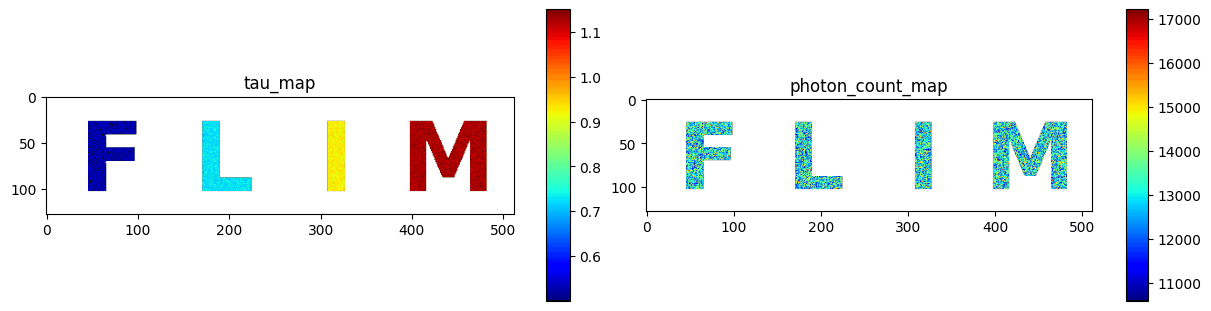

In [8]:
gt_maps = gt_data["results"]["maps"]
jet_m = ColorProcessor().lowest_zero("jet")

_ = DataViewer().display_data(
    [gt_maps["tau_map"], gt_maps["photon_count_map"]],
    structure=(1, 2),
    coord=None,
    data_names=["tau_map", "photon_count_map"],
    cmaps=[jet_m] * 2,
    v_ranges=None,
    figsize=(12, 3),
    normalize=False,
    yscale="linear",
)

Check the decay, IRF, and fit at a randomly selected pixel.

the non-zero pixel selected for probing is (83, 57)


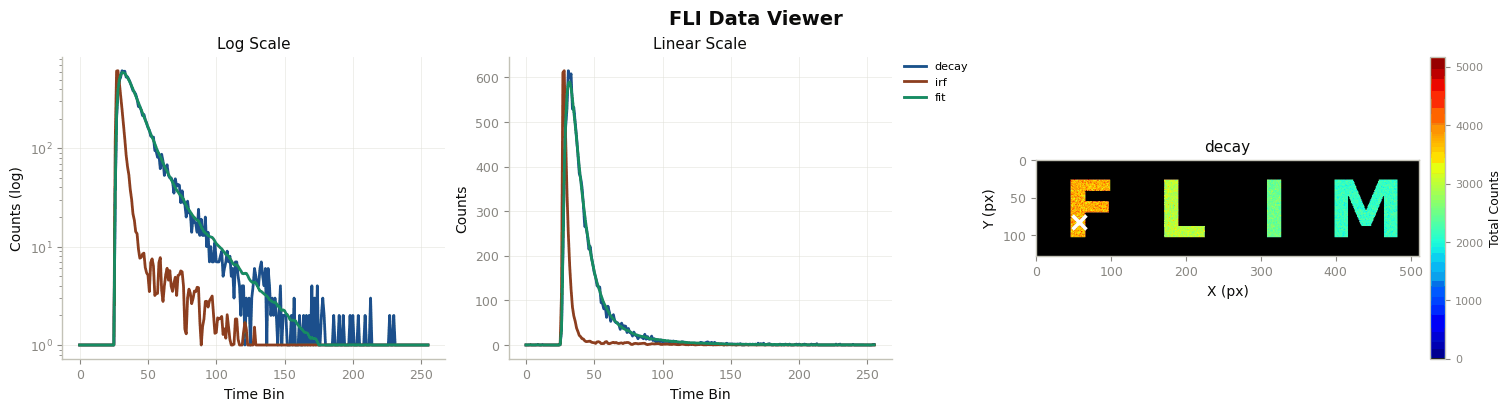

INFO:pyfli:
  Pixel (83, 57)
  ─────────────────────
  A         11702.9219
  α         —
  τ₁        0.5313
  τ₂        —
  R²        —
  Red.χ²    —
  Raw.χ²    —
  Pearson   —
  v-shift   0.0800
  h-shift   0.0000
  ─────────────────────



In [9]:
_decay = gt_data["raw_data"]["decay"]
_irf = gt_data["raw_data"]["irf"]
x, y = random_true_pixel(b_bool_mask)
TRs = gt_data["results"]["TR_maps"]
print(f"the non-zero pixel selected for probing is ({x}, {y})")
irf_norm = Normalization(_irf).norm_scale(_decay)
DataViewer().plot_fli_px(
    data_list=[_decay, irf_norm, TRs["fit_map"], TRs["residual_map"]],
    pixel=(x, y),
    mode=[0, 1, 2],
    mode2=[1],
    names=["decay", "irf", "fit"],
    cmap=jet_m,
)
_ = MessageDisplay().get_pixel_summary(data_maps=gt_maps, px=(x, y))

## Choosing the tail window

The window is set once for the whole image from the peak of the summed decay, so every pixel is fitted over the same gates:

- `peak_gate`: the gate where the summed decay of all letter pixels peaks;
- the tail is `peak_gate ... num_gates - 1`; the fit window runs from `TAIL_WINDOW[0]` (20%) to `TAIL_WINDOW[1]` (80%) of the tail;
- `FIT_INDICES = (tail_start, tail_end)` is passed to every fit below as `fit_indices` (the end gate is exclusive).

Change `TAIL_WINDOW` to fit another part of the tail.

peak gate 32 (1.56 ns); tail = 224 gates
fit window: gates 54-210 (2.64-10.25 ns), 31.3% of the detected counts


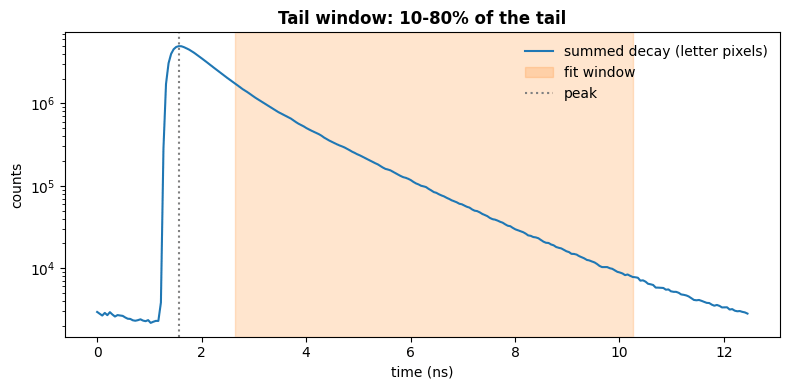

In [10]:
TAIL_WINDOW = (0.1, 0.8)

summed_decay = _decay[b_bool_mask.astype(bool)].sum(axis=0)
peak_gate = int(np.argmax(summed_decay))
tail_length = num_gates - peak_gate
tail_start = peak_gate + int(round(TAIL_WINDOW[0] * tail_length))
tail_end = peak_gate + int(round(TAIL_WINDOW[1] * tail_length))
FIT_INDICES = (tail_start, tail_end)

t_ns = np.arange(num_gates) * gate_delay
in_window = summed_decay[tail_start:tail_end].sum() / summed_decay.sum()
print(f"peak gate {peak_gate} ({t_ns[peak_gate]:.2f} ns); tail = {tail_length} gates")
print(
    f"fit window: gates {tail_start}-{tail_end - 1} "
    f"({t_ns[tail_start]:.2f}-{t_ns[tail_end - 1]:.2f} ns), "
    f"{100 * in_window:.1f}% of the detected counts"
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(t_ns, np.clip(summed_decay, 1, None), label="summed decay (letter pixels)")
ax.axvspan(t_ns[tail_start], t_ns[tail_end - 1], color="tab:orange", alpha=0.2, label="fit window")
ax.axvline(t_ns[peak_gate], color="grey", linestyle=":", label="peak")
ax.set_xlabel("time (ns)")
ax.set_ylabel("counts")
ax.set_title(
    f"Tail window: {int(100 * TAIL_WINDOW[0])}-{int(100 * TAIL_WINDOW[1])}% of the tail",
    fontweight="bold",
)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Single-pixel fit over the tail window: NLSF vs MLE

Before fitting the whole image, `FittingComparator` fits one randomly selected pixel with both estimators and plots the fits side by side:

- `"least_squares"` uses `BaseFLIFitter` (NLSF)
- `"poisson"` uses `MLEFLIFitter` (Poisson MLE)

`p0` (initial guess) and `bounds` are left as `None`, so the fitter derives its own initial guess from the data. For a mono-exponential model the parameters are `[S, tau, v_shift, h_shift]`, and both can be passed in that order.

In [11]:
SHIFT_METHOD = "circular"


┌──────────────────────────────────────────────────────────────┐
│  FLI Fitting Results  |  MONO-EXPONENTIAL                    │
│  2 methods queued                                            │
└──────────────────────────────────────────────────────────────┘


┌────────────────┬──────┬─────────┬──────────┬─────────┬──────────┬──────────┬─────────┬──────────┐
│ Method         │ Type │       A │        τ │      R² │   Red.χ² │   Raw.χ² │ v-shift │  h-shift │
├────────────────┼──────┼─────────┼──────────┼─────────┼──────────┼──────────┼─────────┼──────────┤
│ LEAST_SQUARES  │ NLSF │ 10483.02 │    1.132 │  0.9829 │   1.1408 │   183.45 │    0.00 │    0.146 │
│ POISSON        │ MLE  │ 10483.98 │    1.132 │  0.9829 │   1.1408 │   183.45 │    0.00 │    0.146 │
└────────────────┴──────┴─────────┴──────────┴─────────┴──────────┴──────────┴─────────┴──────────┘



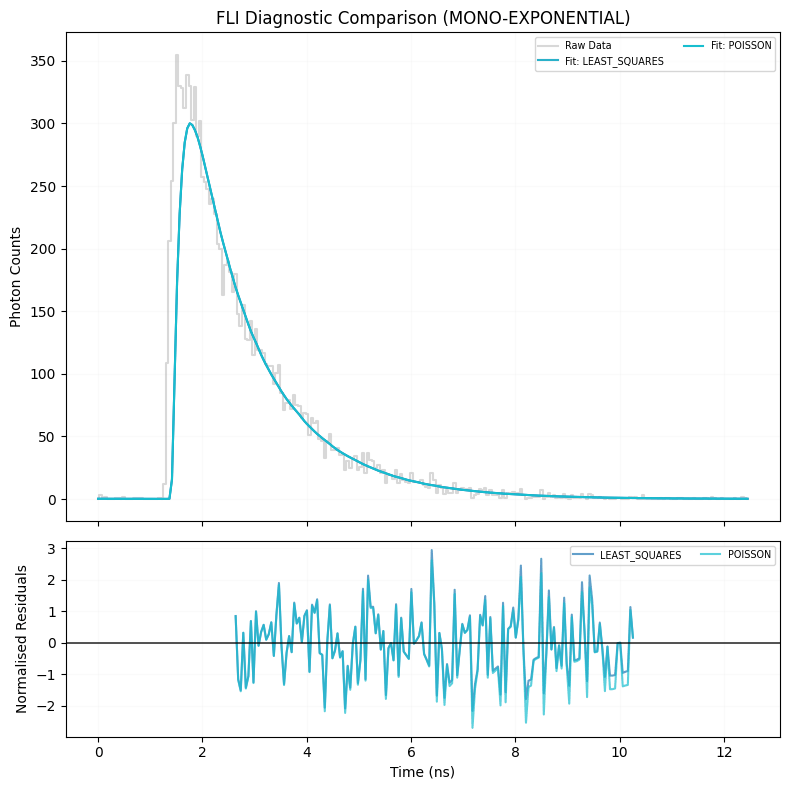

In [12]:
p0 = None
bounds = None

xd, yd = random_true_pixel(b_bool_mask)
pixel_decay = _decay[xd, yd, :]
pixel_irf = _irf[xd, yd, :]

comparator = FittingComparator(freq, BaseFLIFitter, MLEFLIFitter)
comp_results_table, comp_fig = comparator.compare_selected(
    ["least_squares", "poisson"],
    y_data=pixel_decay,
    irf_data=pixel_irf,
    model_type=MODEL_TYPE,
    shift_method=SHIFT_METHOD,
    p0=p0,
    bounds=bounds,
    yscale="linear",
    plot=True,
    fit_indices=FIT_INDICES,
)

## Whole-image fitting

Each pixel is fitted independently and in parallel on the CPU, over the tail window only (`fit_indices=FIT_INDICES`):

- `FLICPUProcessor(freq, fitter_class)` spreads the per-pixel fits over `n_jobs` worker processes. The fitter class sets the estimator family.
- `BinnedFLIFitter(..., bin_radius=0)` is the image-level entry point. A `bin_radius` of 0 fits every pixel as-is, and a larger radius sums each pixel with its neighbours first to raise the photon count.
- `max_iter` caps the optimizer's function evaluations per pixel.

On a machine with a CUDA GPU, `FLIGPUProcessor` can be used in place of `FLICPUProcessor` to fit all pixels as one batch.

### NLSF

In [13]:
MAX_ITER = 1000
N_JOBS = 7

nlsf_fitter = BinnedFLIFitter(FLICPUProcessor(freq, BaseFLIFitter), bin_radius=0)
results_nlsf = nlsf_fitter.fit(
    b_img=_decay,
    b_irf=_irf,
    estimator="least_squares",
    model_type=MODEL_TYPE,
    shift_method=SHIFT_METHOD,
    n_jobs=N_JOBS,
    data_name="simulated_nlsf",
    max_iter=MAX_ITER,
    fit_indices=FIT_INDICES,
)

INFO:pyfli:Engine: CPU Parallel Processor (via FLICPUProcessor)
Fitting Pixels (least_squares): 100%|██████████| 10241/10241 [01:41<00:00, 100.91px/s]


### MLE

The same pipeline is run with `MLEFLIFitter` and the `"poisson"` estimator. MLE takes longer per pixel than NLSF.

In [14]:
mle_fitter = BinnedFLIFitter(FLICPUProcessor(freq, MLEFLIFitter), bin_radius=0)
results_mle = mle_fitter.fit(
    b_img=_decay,
    b_irf=_irf,
    estimator="poisson",
    model_type=MODEL_TYPE,
    shift_method=SHIFT_METHOD,
    n_jobs=N_JOBS,
    data_name="simulated_mle",
    max_iter=MAX_ITER,
    fit_indices=FIT_INDICES,
)

INFO:pyfli:Engine: CPU Parallel Processor (via FLICPUProcessor)
Fitting Pixels (poisson): 100%|██████████| 10241/10241 [04:13<00:00, 40.47px/s]


In [15]:
import pandas as pd

from pyfli.solver import FLICPUProcessor, MLEFLIFitter

check_px = np.argwhere(b_bool_mask)
check_px = check_px[np.random.default_rng(SEED).choice(len(check_px), size=min(300, len(check_px)), replace=False)]
check_decay = _decay[check_px[:, 0], check_px[:, 1]][:, None, :]
check_irf = _irf[check_px[:, 0], check_px[:, 1]][:, None, :]
check_keys = (
    ["tau1_map", "tau2_map", "alpha1_map", "tau_mean_map"] if MODEL_TYPE == "bi-exponential" else ["tau_map"]
)
rows = []
for method in ["zero_pad", "circular"]:
    fitted = FLICPUProcessor(freq, MLEFLIFitter).process_image(
        check_decay,
        check_irf,
        mask=np.ones(check_decay.shape[:2], dtype=bool),
        model_type=MODEL_TYPE,
        estimator="poisson",
        n_jobs=7,
        shift_method=method,
    )["results"]["maps"]
    row = {"shift_method": method}
    for key in check_keys:
        rel = fitted[key][:, 0] / gt_maps[key][check_px[:, 0], check_px[:, 1]] - 1.0
        name = key.replace("_map", "")
        row[f"{name} bias (%)"] = 100 * np.median(rel)
        row[f"{name} spread (%)"] = 100 * (np.percentile(rel, 75) - np.percentile(rel, 25))
    rows.append(row)
pd.DataFrame(rows).set_index("shift_method").round(2)

Fitting Pixels (poisson):   0%|          | 0/300 [00:00<?, ?px/s]

Fitting Pixels (poisson): 100%|██████████| 300/300 [00:06<00:00, 47.96px/s]


,tau bias (%),tau spread (%)
shift_method,,
zero_pad,-0.39,1.64
circular,-0.14,1.67


## Comparing the results

Every fit result has the same layout: `results["results"]["maps"]` holds the parameter maps (`tau_map`, `R2_map`, `reduced_chi2_map`, ...), and `results["results"]["TR_maps"]` holds the per-pixel fitted curves (`fit_map`) and residuals (`residual_map`).

### Lifetime maps

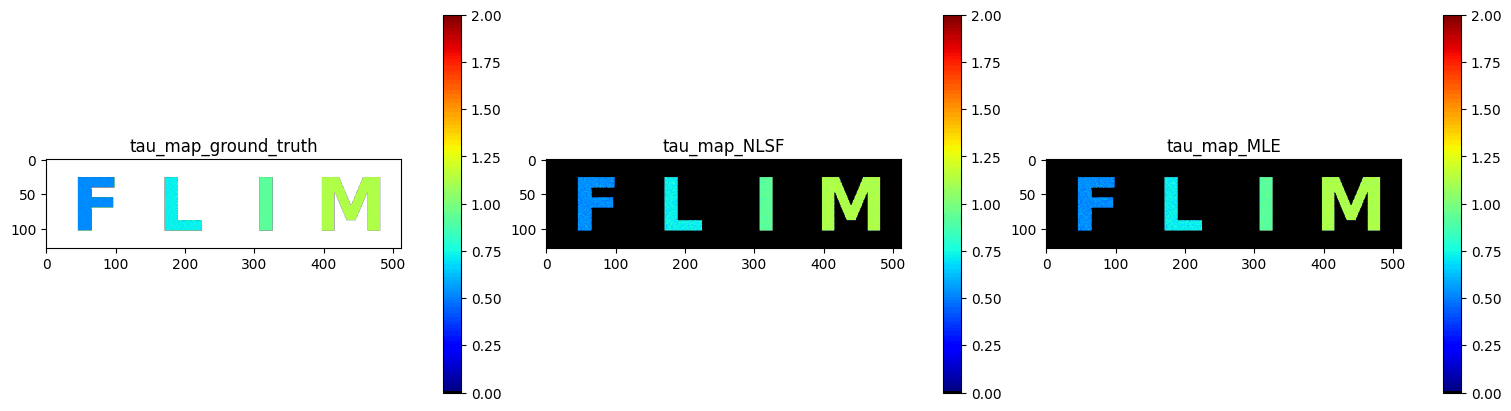

In [16]:
experiments = {"NLSF": results_nlsf, "MLE": results_mle}
all_datasets = [res["results"]["maps"] for res in experiments.values()]
all_fitset = [res["results"]["TR_maps"] for res in experiments.values()]

_ = DataViewer().display_data(
    [gt_maps["tau_map"]] + [maps["tau_map"] for maps in all_datasets],
    structure=(1, 3),
    coord=None,
    data_names=["tau_map_ground_truth"] + [f"tau_map_{name}" for name in experiments],
    cmaps=[jet_m] * 3,
    v_ranges=[(0, 2)] * 3,
    figsize=None,
    normalize=False,
    yscale="linear",
)

### Lifetime distributions

`Plotter` compares the lifetime values of the letter pixels across the sources. The `operations` dict is applied to every source: it keeps only pixels inside the mask, drops failed fits (NaN or zero) and discards values outside the threshold range. A list of dicts, one per source, can be passed instead to filter each source differently.

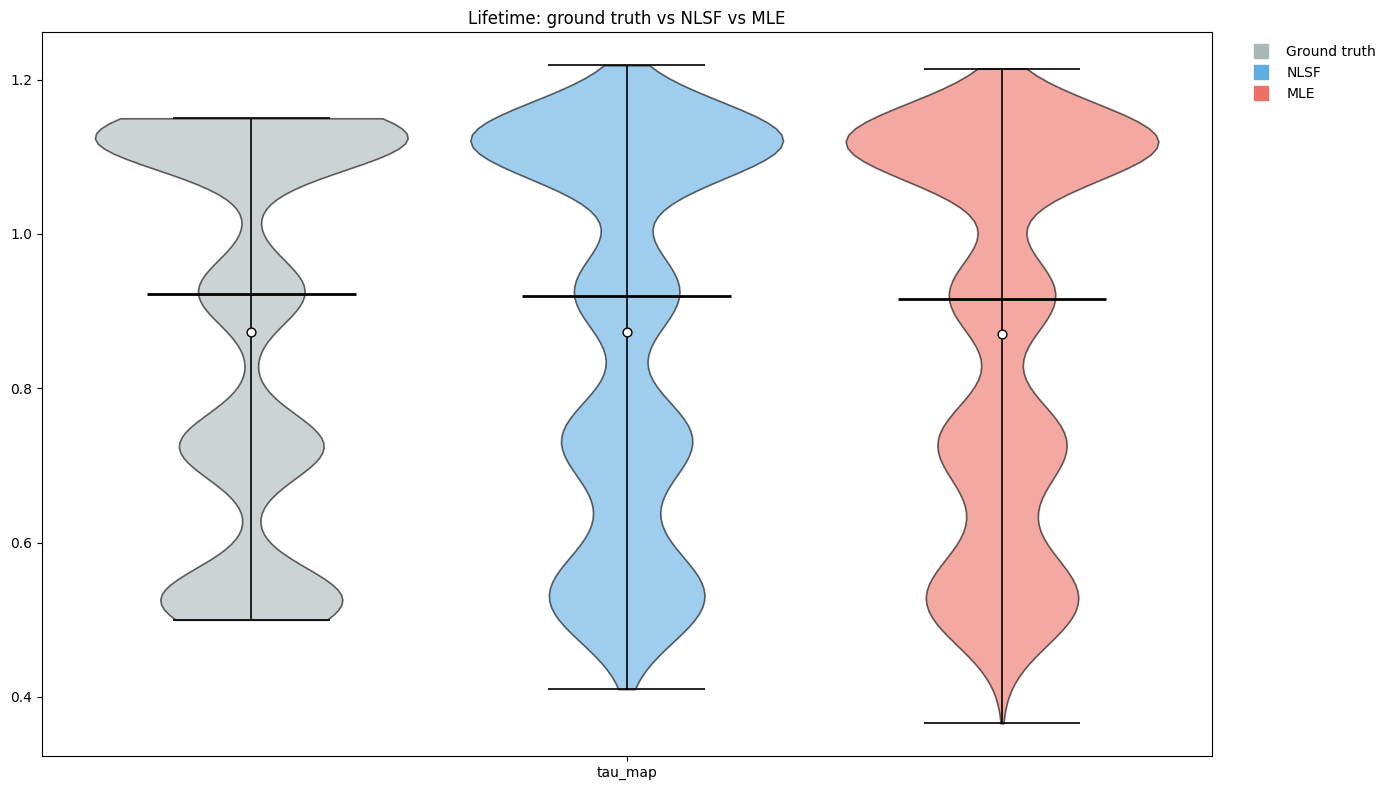

In [17]:
names = ["Ground truth"] + list(experiments)
plotter_ops = {
    "mask": b_bool_mask.ravel(),
    "remove_nan": True,
    "remove_zero": True,
    "threshold": (0, 7),
}

painter = Plotter(
    gt_maps,
    *all_datasets,
    values=["tau_map"],
    style_config=["#AAB7B8", "#5DADE2", "#EC7063"],
    source_names=names,
    operations=plotter_ops,
)

fig = painter.make_plot(
    title="Lifetime: ground truth vs NLSF vs MLE",
    graph_type="violin",
    point_type="strip",
    show_mean=True,
    show_median=True,
    show_significance=True,
    test_type="none",
    correction=False,
)

`graph_type` can also be `"box"`, `"swarm"`, `"overlay"`, `"raincloud"` or `"kde"`. Setting `test_type` to `"paired"` or `"welch"` adds significance tests between the sources.

### Fits at a single pixel

`plot_pixel_diagnostic` overlays the NLSF and MLE fitted curves on the measured decay at one pixel, with the residuals below.

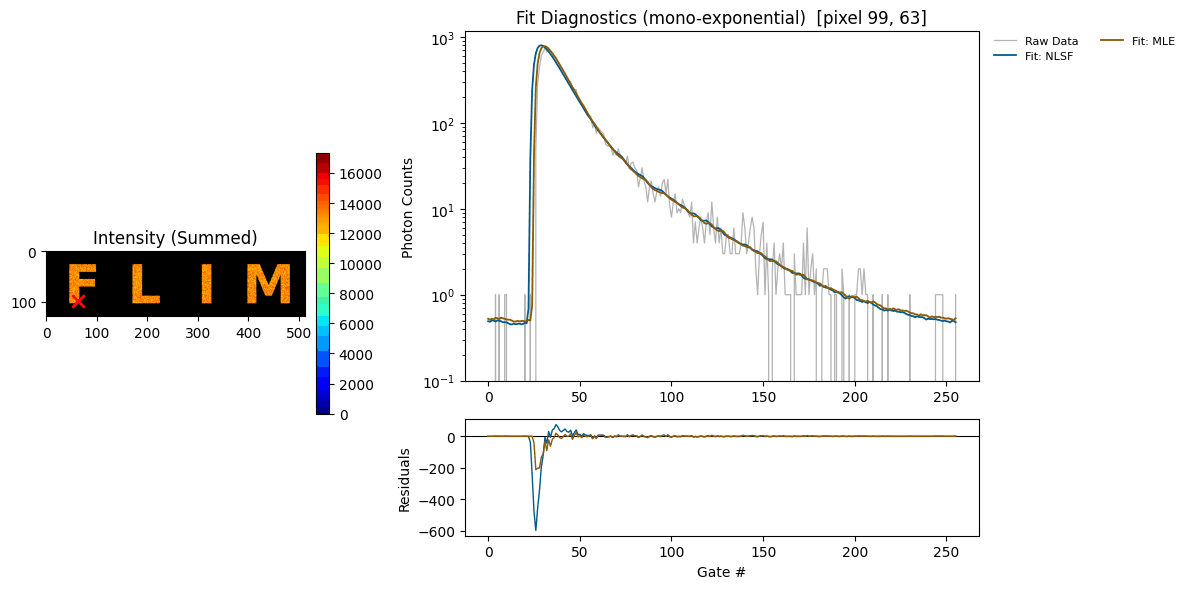

In [18]:
x, y = random_true_pixel(b_bool_mask)
_ = plot_pixel_diagnostic(
    _decay,
    all_fitset,
    list(experiments),
    mask=b_bool_mask,
    pixel=(x, y),
    t=None,
    yscale="log",
    raw_style="line",
    model_type=MODEL_TYPE,
)